# 03 — ARIMA/SARIMA: identificação, ajuste e previsão

Ajuste **só no treino** (até 2016-03-27); previsão dos 28 dias de validação. O código de identificação e ajuste é o do `run.py` (importado), para que este notebook reproduza exatamente `metricas.csv`.

**Sem vazamento:** a identificação (ACF/PACF, grid de AIC) e o ajuste usam só `treino`. A validação entra apenas depois, em `calcular_metricas`, para avaliar as previsões já geradas. A ordem **não** é escolhida olhando o erro na validação.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1]  # notebook roda a partir de src/entrega_1
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ts_utils import BASELINES, M, SERIES, calcular_baselines, calcular_metricas, carregar_dados, escala_mase

treino, val = carregar_dados(RAIZ)
h = len(val)
print(f"Treino: {treino.date.min().date()} a {treino.date.max().date()} ({len(treino)} dias)")
print(f"Validação: {val.date.min().date()} a {val.date.max().date()} ({h} dias)")

import run  # funções do pipeline (identificar_sarima, prever_sarima); main() não roda no import
# run.py força o backend Agg no import; volta ao inline do notebook
%matplotlib inline
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Treino: 2011-01-29 a 2016-03-27 (1885 dias)
Validação: 2016-03-28 a 2016-04-24 (28 dias)


## 1. Identificação

**Estacionariedade e diferenciação.** O ACF das três séries tem picos em 7, 14, 21, 28 (sazonalidade semanal forte), então D=1 com m=7. O ADF no nível não rejeita raiz unitária em `store_total` e `FOODS`; em `HOBBIES` é limítrofe (ver `saidas/diagnostico_testes.csv`). Abaixo, ACF/PACF após diff(1) e diff sazonal(7).

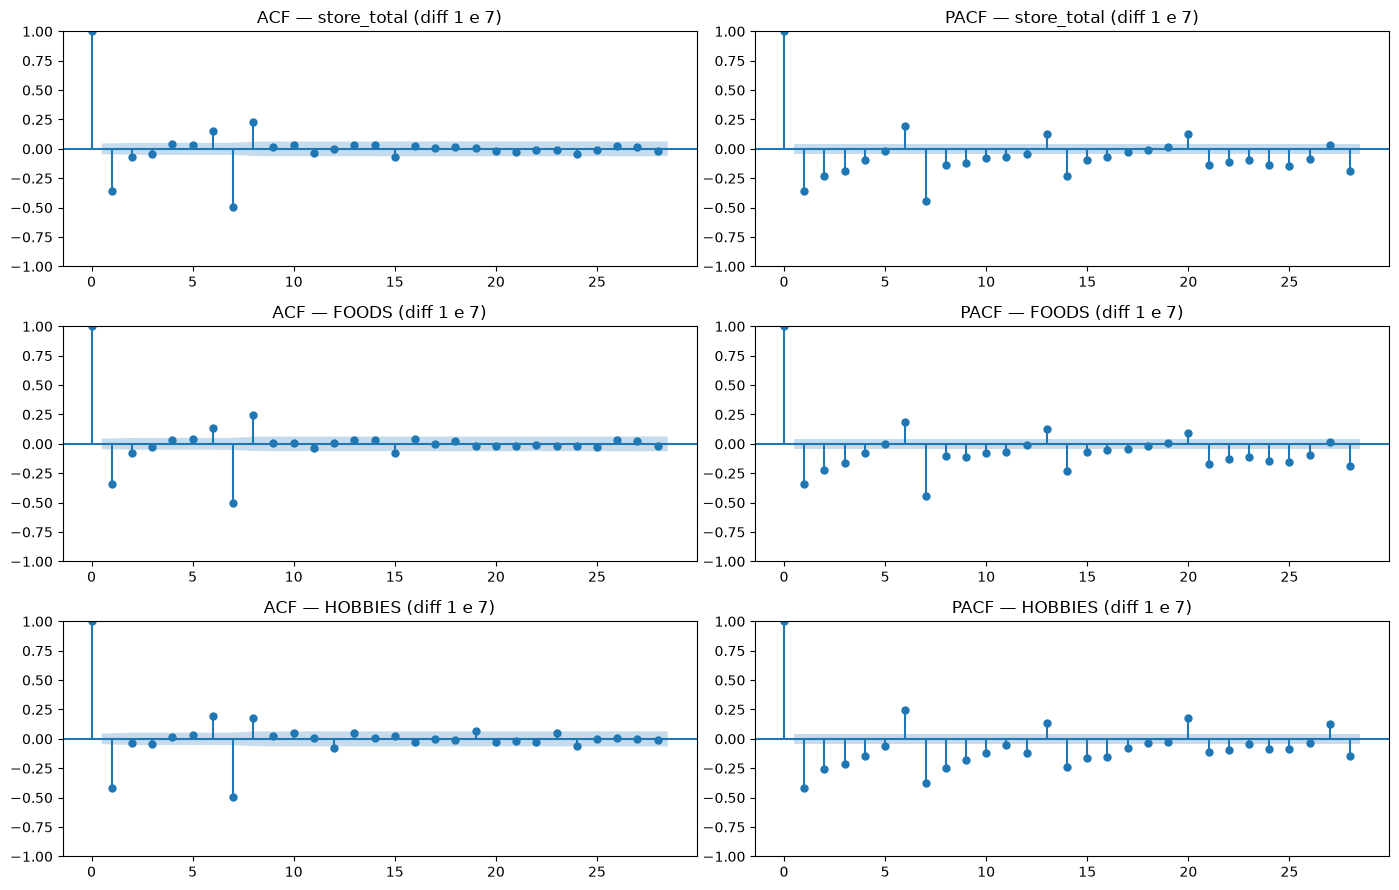

In [2]:
fig, ax = plt.subplots(3, 2, figsize=(14, 9))
for i, s in enumerate(SERIES):
    dif = treino.set_index("date")[s].diff().diff(M).dropna().to_numpy()
    plot_acf(dif, lags=28, ax=ax[i, 0], title=f"ACF — {s} (diff 1 e 7)")
    plot_pacf(dif, lags=28, ax=ax[i, 1], method="ywm", title=f"PACF — {s} (diff 1 e 7)")
fig.tight_layout()

**Leitura.** Em todas as séries o ACF diferenciado tem pico negativo no lag 1 (≈ −0,4) e no lag 7 (≈ −0,5): estrutura MA(1) × MA sazonal(1), o "airline model" (0,1,1)(0,1,1)₇ como ponto de partida. O PACF decai devagar, o que deixa espaço para termos AR. Isso restringe a grade a p,q ≤ 2, P,Q ≤ 1, d ∈ {0,1}, D=1; dentro dela escolhe-se o menor AIC (72 modelos por série).

**Por que AIC e não o erro de validação?** Escolher a ordem pela validação seria vazamento (a validação viraria parte do ajuste e a métrica ficaria otimista). O AIC é calculado só no treino. Cuidados: (i) ordens vizinhas diferem por menos de 1–2 pontos de AIC (ver o top 3 abaixo), então a escolha entre elas não é conclusiva; (ii) comparar AIC entre d=0 e d=1 é delicado porque a diferenciação muda a amostra efetiva, por isso a escolha de d em `HOBBIES` é a menos firme; (iii) os modelos usam as restrições padrão de estacionariedade/invertibilidade do `SARIMAX`, e só entram na disputa os ajustes que convergem.

In [3]:
ordens, resultados = {}, {}
for s in SERIES:
    y = treino[s].to_numpy(float)
    ordem, sazonal, aic, bic, _ = run.identificar_sarima(y, s)
    ordens[s] = (ordem, sazonal)
    print(f"  -> escolhida: SARIMA{ordem}{sazonal}  AIC={aic:.1f}\n")

  store_total: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=28143.93
    SARIMA(2, 1, 2)(1, 1, 1, 7)  AIC=28144.04
    SARIMA(1, 1, 1)(1, 1, 1, 7)  AIC=28144.27
  -> escolhida: SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=28143.9



  FOODS: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=27051.50
    SARIMA(1, 1, 1)(1, 1, 1, 7)  AIC=27054.08
    SARIMA(2, 1, 2)(1, 1, 1, 7)  AIC=27059.40
  -> escolhida: SARIMA(2, 1, 1)(1, 1, 1, 7)  AIC=27051.5



  HOBBIES: 72/72 ajustes convergiram. Top 3 por AIC:
    SARIMA(2, 0, 1)(0, 1, 1, 7)  AIC=22117.22
    SARIMA(2, 0, 1)(1, 1, 1, 7)  AIC=22118.83
    SARIMA(1, 0, 2)(0, 1, 1, 7)  AIC=22122.17
  -> escolhida: SARIMA(2, 0, 1)(0, 1, 1, 7)  AIC=22117.2



## Diagnóstico dos resíduos do ajuste final

O teste de Ljung-Box (H0: resíduos sem autocorrelação) é calculado nos lags 7, 14 e 28 sobre os resíduos do modelo ajustado **no treino**. Os primeiros 8 resíduos são descartados porque o filtro de Kalman ainda está inicializando com as diferenciações.

In [4]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ajustes = {}
tabela = []
for s in SERIES:
    y = treino[s].to_numpy(float)
    ajustes[s] = run.SARIMAX(y, order=ordens[s][0], seasonal_order=ordens[s][1]).fit(disp=False, maxiter=200)
    res = ajustes[s].resid[8:]
    lb = acorr_ljungbox(res, lags=[7, 14, 28])
    tabela.append({"series": s, **{f"LB p (lag {l})": p for l, p in zip(lb.index, lb["lb_pvalue"])}})
pd.DataFrame(tabela).round(4)

,series,LB p (lag 7),LB p (lag 14),LB p (lag 28)
0,store_total,0.9986,0.1189,0.0000
1,FOODS,0.9016,0.0019,0.0000
2,HOBBIES,0.5635,0.1444,0.0279


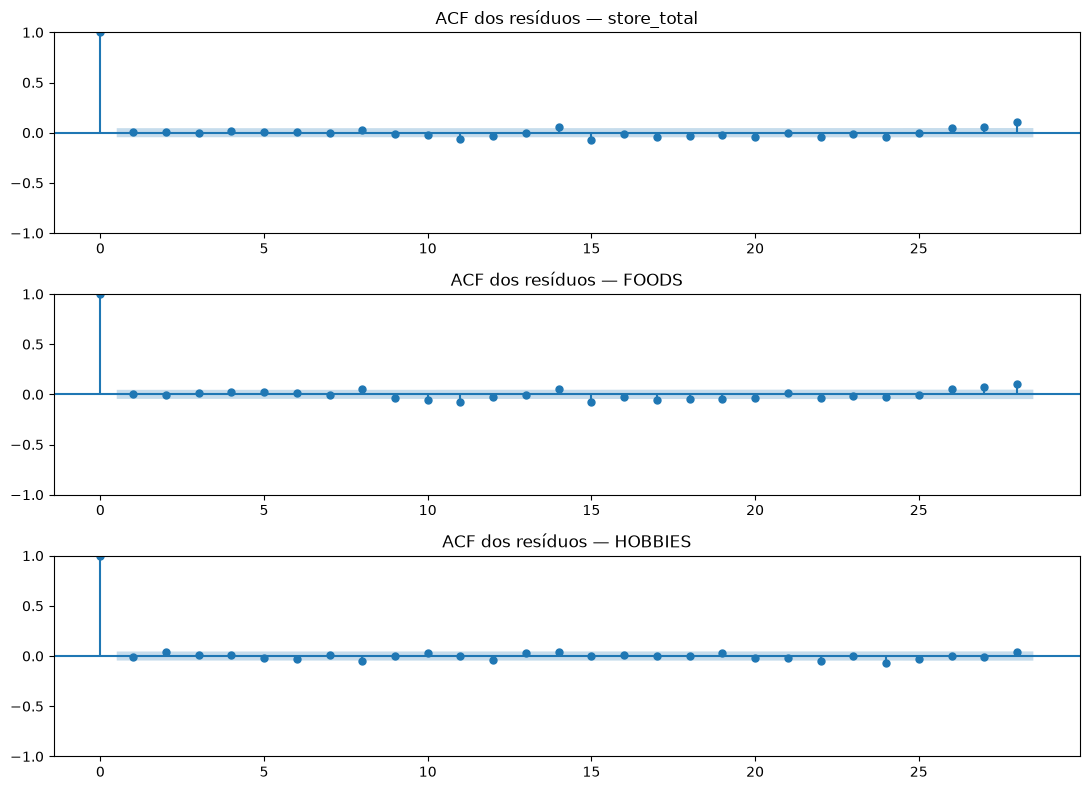

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(11, 8))
for a, s in zip(ax, SERIES):
    plot_acf(ajustes[s].resid[8:], lags=28, ax=a, title=f"ACF dos resíduos — {s}")
fig.tight_layout()

**Leitura dos resíduos.** No lag 7 o Ljung-Box **não rejeita** nas três séries (p = 0,999, 0,90 e 0,56): o ciclo semanal foi bem capturado. No lag 14 só `FOODS` rejeita (p ≈ 0,002). No lag 28 as três rejeitam (p < 0,001 em `store_total` e `FOODS`; p ≈ 0,03 em `HOBBIES`). Ou seja, sobra alguma autocorrelação em lags mais longos. É plausível: os zeros de Natal são outliers grandes, e feriados e promoções móveis não são capturados por um SARIMA sem regressores (o enunciado não os exige). Isto limita a confiança nas previsões mais distantes do horizonte e fica registrado como limitação, sem alterar o modelo escolhido.

## 2. Previsão (28 dias) e métricas

In [6]:
prev_sarima, linhas = {}, []
for s in SERIES:
    y_tr, y_va = treino[s].to_numpy(float), val[s].to_numpy(float)
    prev_sarima[s] = run.prever_sarima(y_tr, *ordens[s], h)
    mae, rmse, mase = calcular_metricas(y_tr, y_va, prev_sarima[s])
    linhas.append({"series": s, "modelo": "sarima", "ordem": f"{ordens[s][0]}{ordens[s][1]}", "mae": mae, "rmse": rmse, "mase": mase})
metricas_sarima = pd.DataFrame(linhas)
metricas_sarima.round(3)

,series,modelo,ordem,mae,rmse,mase
0,store_total,sarima,"(2, 1, 1)(1, 1, 1, 7)",276.869,363.834,0.636
1,FOODS,sarima,"(2, 1, 1)(1, 1, 1, 7)",186.076,231.547,0.544
2,HOBBIES,sarima,"(2, 0, 1)(0, 1, 1, 7)",75.726,95.194,0.829


## 3. Conferência com o `metricas.csv` oficial e comparação com os baselines

In [7]:
oficial = pd.read_csv(RAIZ / "metricas.csv")
ref = oficial[oficial.modelo == "sarima"].reset_index(drop=True)
assert np.allclose(ref[["mae", "rmse", "mase"]], metricas_sarima[["mae", "rmse", "mase"]], rtol=1e-4)
print("OK: SARIMA do notebook = SARIMA de metricas.csv\n")
oficial.pivot(index="modelo", columns="series", values="mase").loc[BASELINES + ["sarima"]].round(2)

OK: SARIMA do notebook = SARIMA de metricas.csv



series,FOODS,HOBBIES,store_total
modelo,,,
media,1.54,1.22,1.87
naive,1.94,1.85,1.98
naive_sazonal,1.01,1.12,1.06
drift,1.94,1.87,1.98
sarima,0.54,0.83,0.64


**Conclusão.** O SARIMA tem o menor MAE, RMSE e MASE nas três séries (MASE < 1 em todas), isto é, melhora o naive sazonal in-sample usado como escala. O naive sazonal é o melhor baseline em `store_total` e `FOODS` (MASE ≈ 1,0); `naive` e `drift` ficam perto de 1,9–2,0 porque ignoram o ciclo semanal. Em `HOBBIES` o naive sazonal e a média têm MASE > 1 (pior que a escala), com resultado misto entre eles: naive sazonal ganha em MAE, média ganha em RMSE. O SARIMA não perde para nenhum baseline em nenhuma série, então não há caso a esconder.

**Limitações.** A validação tem só 28 dias (4 ciclos semanais) e um único corte temporal, sem backtesting em múltiplas origens nem intervalos de previsão. A margem do SARIMA sobre os baselines é grande, mas a ordem exata entre modelos próximos em `HOBBIES` não é garantida em outros períodos. Zeros de Natal e feriados móveis ficam sem tratamento explícito.

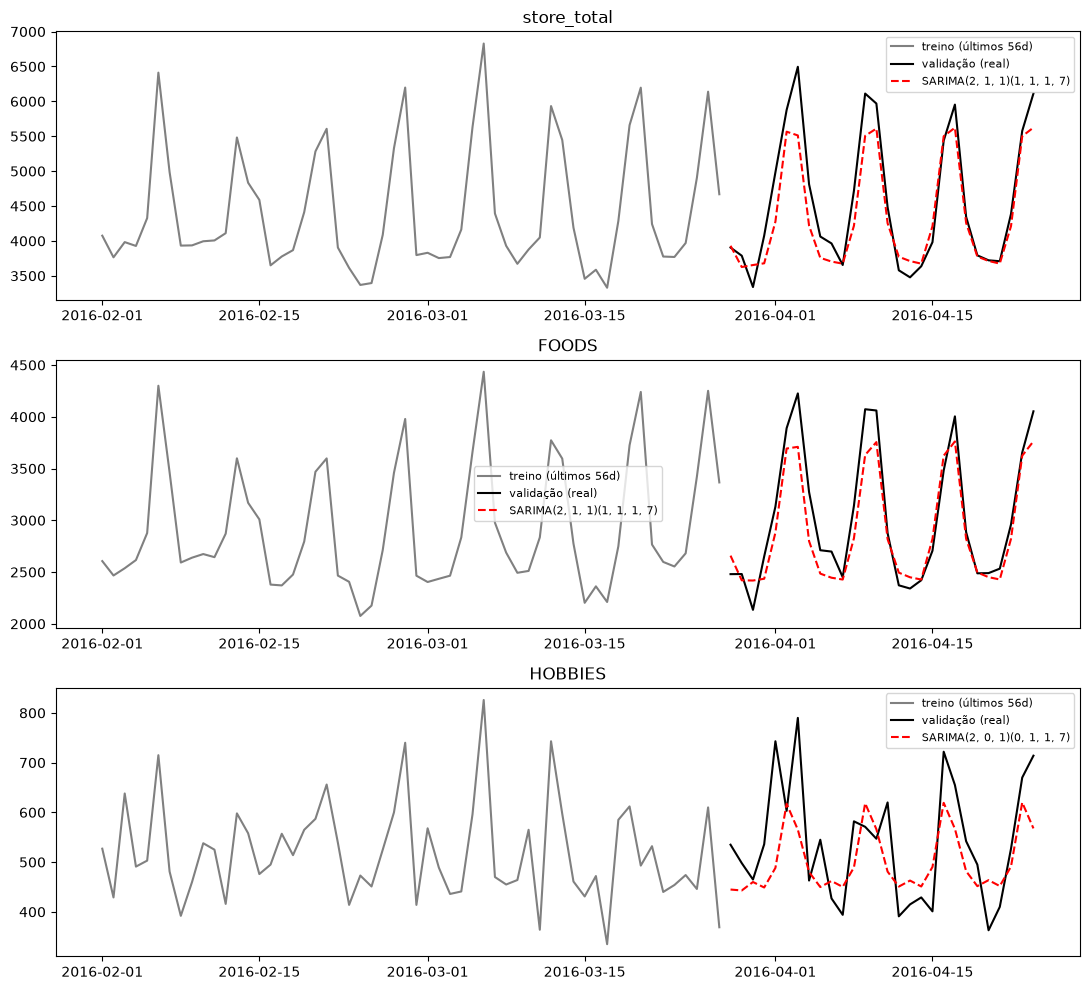

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
for a, s in zip(ax, SERIES):
    a.plot(treino.date.tail(56), treino[s].tail(56), color="gray", label="treino (últimos 56d)")
    a.plot(val.date, val[s], color="black", label="validação (real)")
    a.plot(val.date, prev_sarima[s], color="red", ls="--", label=f"SARIMA{ordens[s][0]}{ordens[s][1]}")
    a.set_title(s); a.legend(fontsize=8)
fig.tight_layout()